## Types of Sequential Data

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

import keras

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.model_selection import ShuffleSplit
from sklearn.tree import DecisionTreeRegressor
from statsmodels.tsa.seasonal import seasonal_decompose
from dateutil.parser import parse
import os
import pathlib
from scipy import signal
from scipy.io import wavfile
import re
import string 

In [8]:
import nltk
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('omw-1.4')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import HashingVectorizer

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LEI\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\LEI\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LEI\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\LEI\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [9]:
sns.set_context('notebook')
sns.set_style('whitegrid')

In [10]:
symbols = {
    'TOT' : "Total", 'XOM' : 'Exxon', 'CVX' : 'Chevron',
    'COP' : 'ConocoPhillips', 'VLO': 'Valero Energy'}

template_name = ("./financial-data/{}.csv")

quotes = {}

for symbol in symbols:

    data = pd.read_csv(template_name.format(symbol), index_col=0, parse_dates=True)
    quotes[symbols[symbol]] = data['open']

quotes = pd.DataFrame(quotes)
quotes.head()

,Total,Exxon,Chevron,ConocoPhillips,Valero Energy
date,,,,,
2003-01-02,71.62,35.00,67.20,48.80,37.04
2003-01-03,72.12,35.25,67.82,49.53,38.13
2003-01-06,72.93,35.45,68.34,49.50,37.37
2003-01-07,72.40,36.05,69.75,49.85,37.46
2003-01-08,69.51,35.15,68.46,48.44,36.51


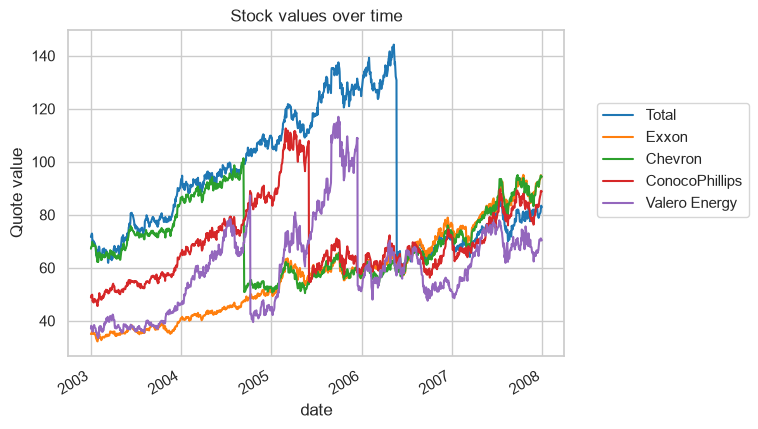

In [11]:
quotes.plot()
plt.ylabel("Quote value")
plt.legend(bbox_to_anchor=(1.05, 0.8), loc="upper left")
_ = plt.title("Stock values over time")

In [12]:
x = quotes.drop(columns=['Chevron'])
y = quotes['Chevron']

xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, shuffle=True, random_state=42
)

x.head(10)

,Total,Exxon,ConocoPhillips,Valero Energy
date,,,,
2003-01-02,71.62,35.00,48.80,37.04
2003-01-03,72.12,35.25,49.53,38.13
2003-01-06,72.93,35.45,49.50,37.37
2003-01-07,72.40,36.05,49.85,37.46
2003-01-08,69.51,35.15,48.44,36.51
2003-01-09,69.52,35.10,47.35,35.92
2003-01-10,70.27,35.35,47.80,37.55
2003-01-13,70.06,35.19,46.90,37.50
2003-01-14,69.11,34.98,47.25,38.35


In [13]:
y.head(10)

date
2003-01-02    67.20
2003-01-03    67.82
2003-01-06    68.34
2003-01-07    69.75
2003-01-08    68.46
2003-01-09    68.15
2003-01-10    68.50
2003-01-13    68.78
2003-01-14    68.23
2003-01-15    68.68
Name: Chevron, dtype: float64

In [14]:
regressor = DecisionTreeRegressor()
cv = ShuffleSplit(random_state=42)

regressor.fit(xtrain, ytrain)

target_predicted = regressor.predict(xtest)

target_predicted = pd.Series(target_predicted, index=ytest.index)
target_predicted

date
2005-03-28    58.11
2003-05-29    72.80
2003-03-18    65.86
2003-04-03    64.80
2007-04-10    75.32
              ...  
2004-03-02    87.19
2007-01-25    72.99
2003-07-25    72.32
2005-05-18    52.51
2007-02-01    72.49
Length: 315, dtype: float64

In [15]:
from sklearn.metrics import r2_score

test_score = r2_score(ytest, target_predicted)
print(f"The R2 on this single split is: {test_score:.2f}")

The R2 on this single split is: 0.85


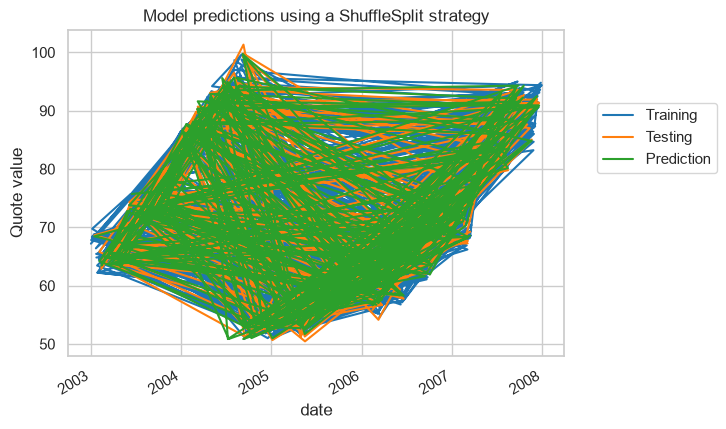

In [17]:
ytrain.plot(label="Training")
ytest.plot(label="Testing")
target_predicted.plot(label="Prediction")

plt.ylabel("Quote value")
plt.legend(bbox_to_anchor=(1.05, 0.8), loc="upper left")
_ = plt.title("Model predictions using a ShuffleSplit strategy")

The R2 on this single split is: -2.38


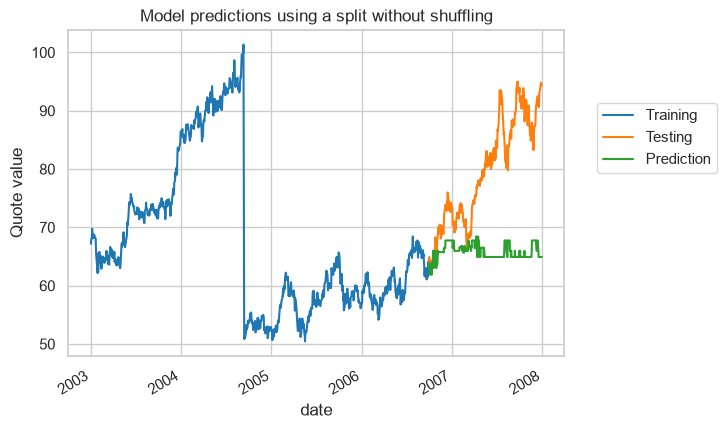

In [18]:
xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, random_state=42, shuffle=False
)

regressor.fit(xtrain, ytrain)
target_predicted = regressor.predict(xtest)

target_predicted = pd.Series(target_predicted, index=ytest.index)
test_score = r2_score(ytest, target_predicted)
print(f"The R2 on this single split is: {test_score:.2f}")

ytrain.plot(label="Training")
ytest.plot(label="Testing")
target_predicted.plot(label="Prediction")

plt.ylabel("Quote value")
plt.legend(bbox_to_anchor=(1.05, 0.8), loc="upper left")
_ = plt.title("Model predictions using a split without shuffling")

### Time Series Decomposition

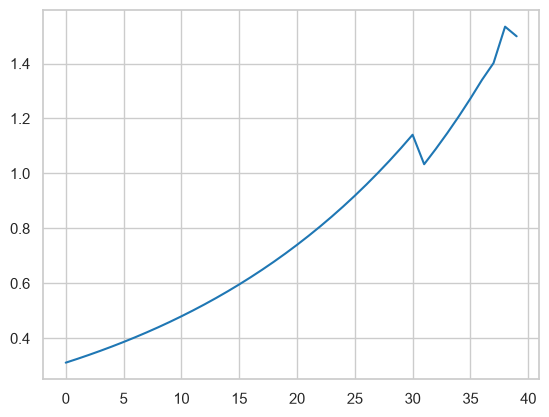

In [19]:
trend = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML311-Coursera/labs/Module4/L1/guinearice.csv', parse_dates=['date'], index_col='date')
plt.plot(trend.values)

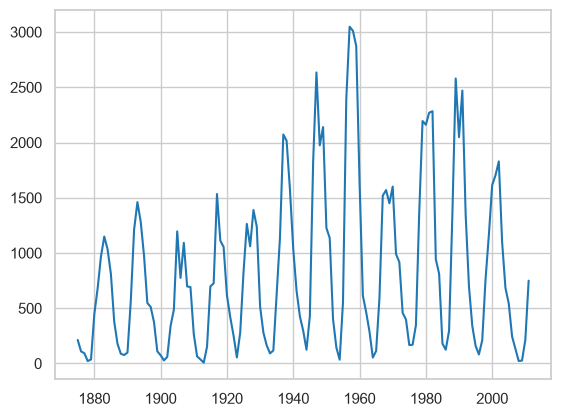

In [20]:
seasonality = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML311-Coursera/labs/Module4/L1/sunspotarea.csv', parse_dates=['date'], index_col='date')
plt.plot(seasonality.value)

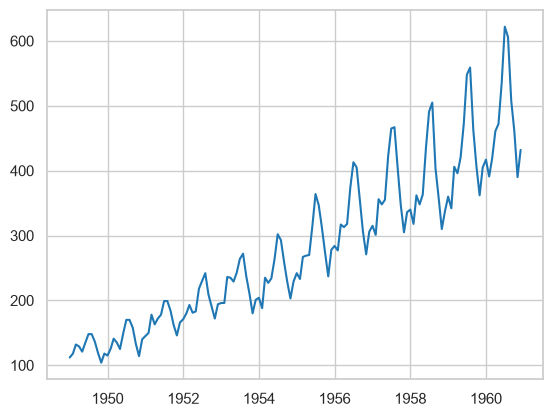

In [21]:
seasonality_trend = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML311-Coursera/labs/Module4/L1/AirPassengers.csv', parse_dates=['date'], index_col='date')
plt.plot(seasonality_trend.value)

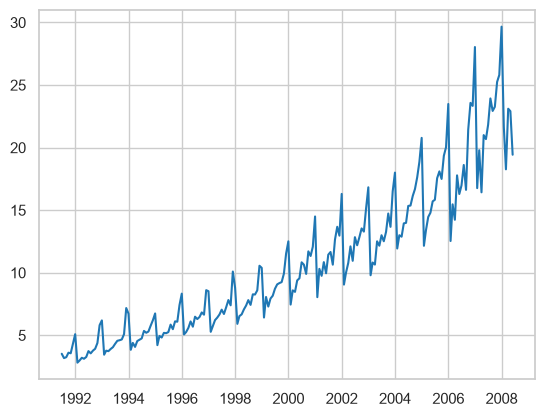

In [22]:
df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML311-Coursera/labs/Module4/L1/a10.csv', parse_dates=['date'], index_col='date')
plt.plot(df.value)

C:\Users\LEI\AppData\Local\Temp\ipykernel_27800\442364513.py:1: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  result_add = seasonal_decompose(df['value'], model='additive', extrapolate_trend='freq')


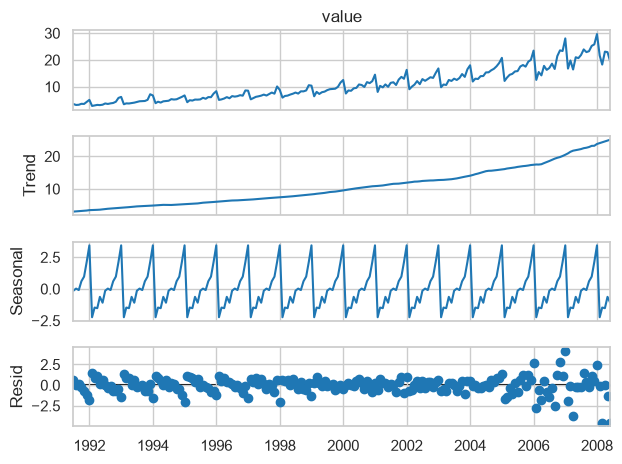

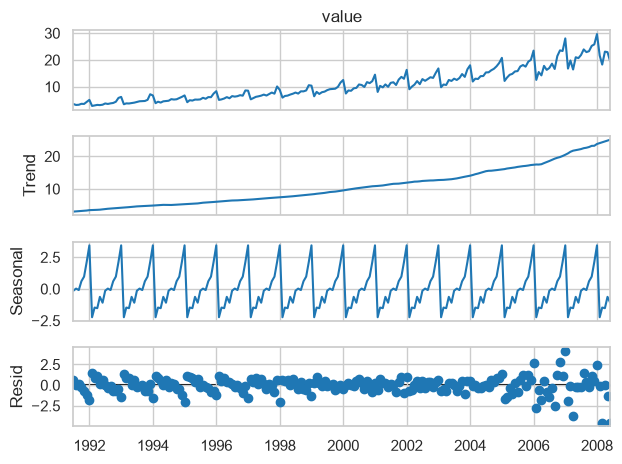

In [25]:
result_add = seasonal_decompose(df['value'], model='additive', extrapolate_trend='freq')
result_add.plot()

C:\Users\LEI\AppData\Local\Temp\ipykernel_27800\3268947768.py:1: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  result_mul = seasonal_decompose(df['value'], model='multiplicative', extrapolate_trend='freq')


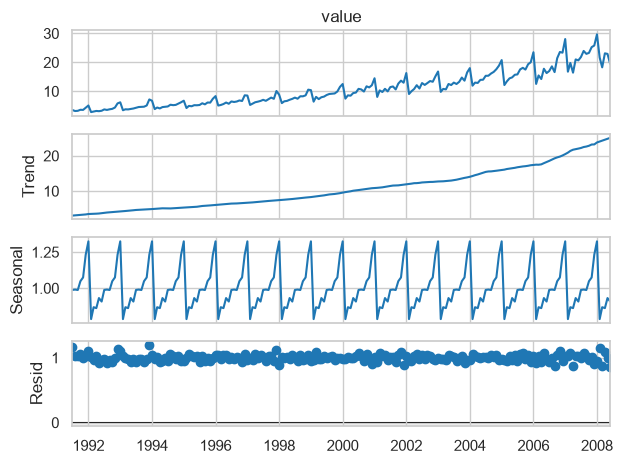

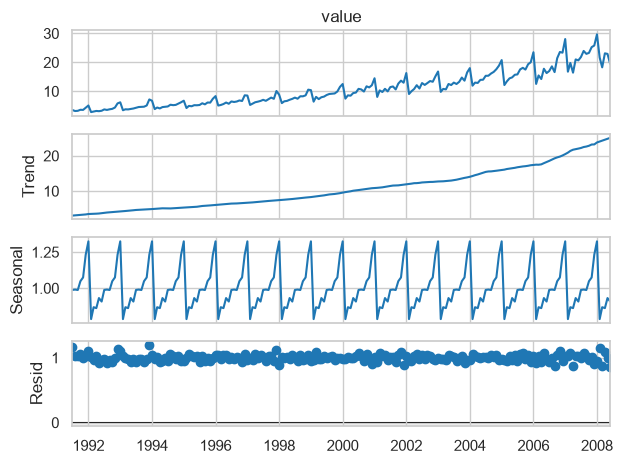

In [26]:
result_mul = seasonal_decompose(df['value'], model='multiplicative', extrapolate_trend='freq')
result_mul.plot()

Text(0.5, 1.0, 'Drug Sales detrended by subtracting the trend component')

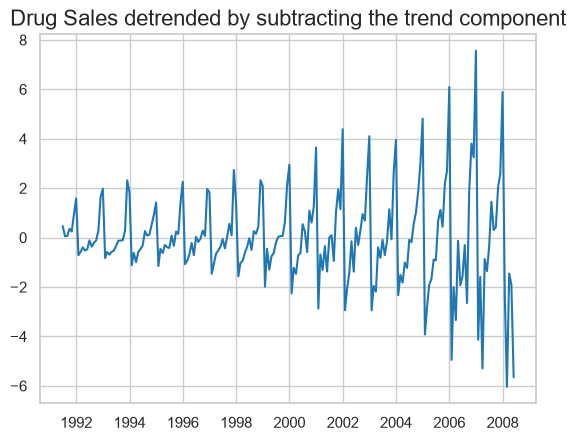

In [27]:
detrended = df.value.values - result_mul.trend
plt.plot(detrended)
plt.title('Drug Sales detrended by subtracting the trend component', fontsize=16)

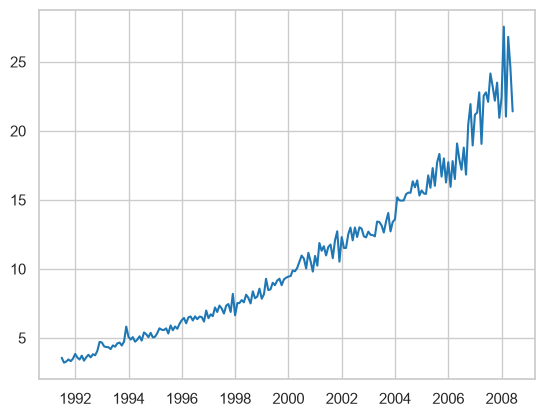

In [28]:
deseasonalized = df.value.values / result_mul.seasonal
plt.plot(deseasonalized)

### Time Series Imputation

In [31]:
df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML311-Coursera/labs/Module4/L1/a10.csv', parse_dates=['date'], index_col='date')

<Axes: title={'center': 'Forward Fill (MSE: 0.0)'}, xlabel='date'>

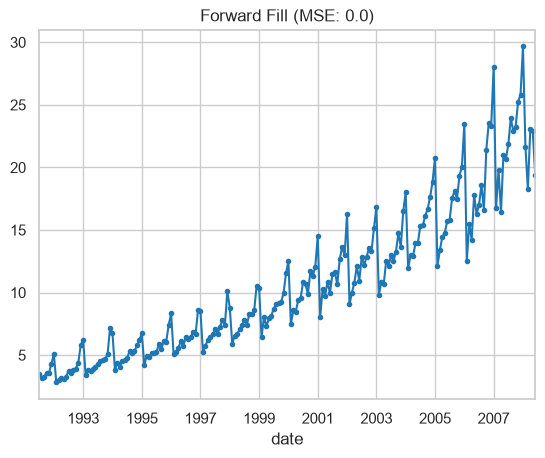

In [30]:
from scipy.interpolate import interp1d
from sklearn.metrics import mean_squared_error

df_ffill = df.ffill()
# Print the MSE between imputed value and ground truth
error = np.round(mean_squared_error(df['value'], df_ffill['value']), 2)
df_ffill['value'].plot(title='Forward Fill (MSE: ' + str(error) +")", label='Forward Fill', style=".-")

In [ ]:
from scipy.interpolate import interp1d
from sklearn.metrics import mean_squared_error

df = pd.read_csv('a10.csv')
df.head()

,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869


<Axes: title={'center': 'Forward Fill (MSE: 0.0)'}>

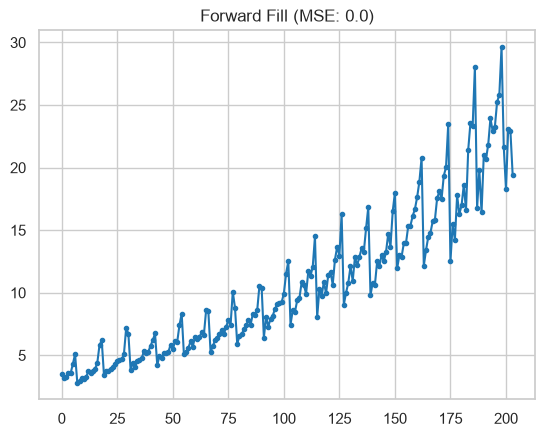

In [33]:
df_ffill = df.ffill()
# Print the MSE between imputed value and ground truth
error = np.round(mean_squared_error(df['value'], df_ffill['value']), 2)
df_ffill['value'].plot(title='Forward Fill (MSE: ' + str(error) +")", label='Forward Fill', style=".-")

<Axes: title={'center': 'Backward Fill (MSE: 0.0)'}>

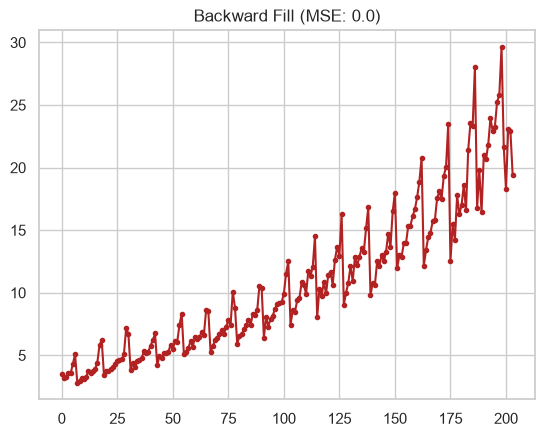

In [35]:
# backward impute
df_bfill = df.bfill()
error = np.round(mean_squared_error(df['value'], df_bfill['value']), 2)
df_bfill['value'].plot(title="Backward Fill (MSE: " + str(error) +")", label='Back Fill', color='firebrick', style=".-")

<Axes: title={'center': 'Linear Fill (MSE: 0.0)'}>

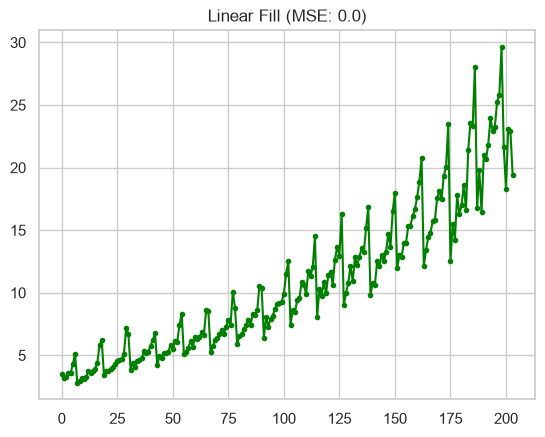

In [ ]:
# linear interpolation impute
df['rownum'] = np.arange(df.shape[0])
df_nona = df.dropna(subset = ['value'])
f = interp1d(df_nona['rownum'], df_nona['value'])
df['linear_fill'] = f(df['rownum'])
error = np.round(mean_squared_error(df['value'], df['linear_fill']), 2)
df['linear_fill'].plot(title="Linear Fill (MSE: " + str(error) +")",label='Cubic Fill', color='green', style=".-")

## Working with Text Data

In [36]:
cols = ['Id', 'Entity', 'Sentiment', 'Tweet']
df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML311-Coursera/labs/Module4/L1/twitter_validation.csv', names = cols, header=None)
df.head(2)

,Id,Entity,Sentiment,Tweet
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...


[Text(0, 0, '172'), Text(0, 0, '266'), Text(0, 0, '277'), Text(0, 0, '285')]

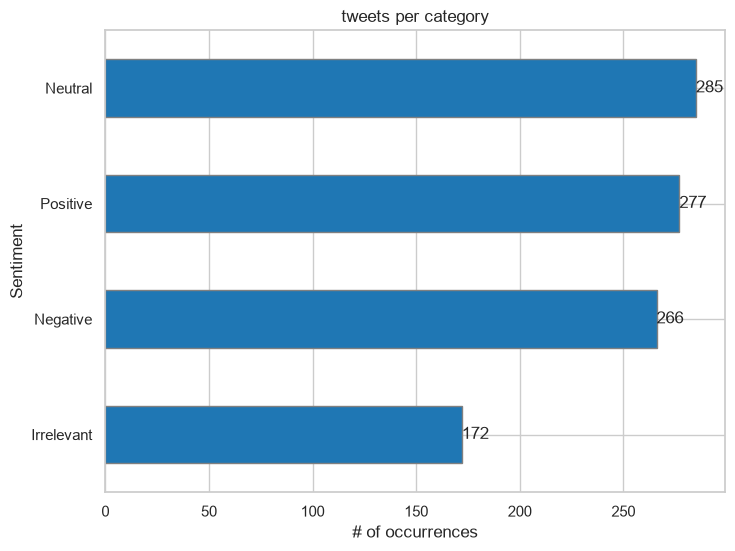

In [39]:
fig, ax = plt.subplots(figsize=(8,6))

df.groupby(['Sentiment']).Tweet.count().sort_values().plot.barh(
    ylim=0, title= 'tweets per category', ax=ax, edgecolor='gray')

plt.xlabel('# of occurrences', fontsize = 12);
plt.bar_label(ax.containers[0])

In [ ]:
def remove_punctutation(tweet):
    regular_punct = list(string.punctuation)
    for punc in regular_punct:
        if punc in tweet:
            tweet = tweet.replace(punc, ' ')

    return tweet.strip().lower()

def remove_stopwords(tweet): 
    en_stops = set(stopwords.words('english'))
    tweet = tweet.split()
    tweet = " ".join([word for word in tweet if not word in en_stops])
    return tweet

def lemma_wordnet(input):
    lem = WordNetLemmatizer()
    return [lem.lemmatize(w) for w in input]

df['Tweet'] = (
    df['Tweet']
    .apply(remove_punctutation)
    .apply(remove_stopwords)
    .apply(word_tokenize)
    .apply(lemma_wordnet)
)

### Vctorization

In [41]:
def combine_text(inp):
    combined = ' '.join(inp)
    return combined


df['Tweet'] = df['Tweet'].apply(combine_text)

cv = CountVectorizer(ngram_range=(1, 1))
X_train_bow = cv.fit_transform(df['Tweet'])
print(X_train_bow[0:10,0:10].todense())

[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]


In [42]:
cv = CountVectorizer(ngram_range=(1, 1))
X_train_bow = cv.fit_transform(df['Tweet'].values.tolist()) 
Y_train_bow = df['Sentiment']
Y_train_bow

0      Irrelevant
1         Neutral
2        Negative
3        Negative
4         Neutral
          ...    
995    Irrelevant
996    Irrelevant
997      Positive
998      Positive
999       Neutral
Name: Sentiment, Length: 1000, dtype: str

In [43]:
cv_bbow = CountVectorizer(ngram_range=(2, 2))
X_train_bbow = cv_bbow.fit_transform(df['Tweet']) 
Y_train_bbow = df['Sentiment']
Y_train_bbow

0      Irrelevant
1         Neutral
2        Negative
3        Negative
4         Neutral
          ...    
995    Irrelevant
996    Irrelevant
997      Positive
998      Positive
999       Neutral
Name: Sentiment, Length: 1000, dtype: str

In [44]:
vectorizer = TfidfVectorizer(use_idf= True, ngram_range=(1, 1))
vectorizer.fit(df)
X_train_tfidf = vectorizer.fit_transform(df['Tweet'])
Y_train_tfidf = df['Sentiment']
Y_train_tfidf

0      Irrelevant
1         Neutral
2        Negative
3        Negative
4         Neutral
          ...    
995    Irrelevant
996    Irrelevant
997      Positive
998      Positive
999       Neutral
Name: Sentiment, Length: 1000, dtype: str